In [1]:
import json

import numpy as np
import pandas as pd
import photolab as lab
from serving import ImageEncoder

rows = lab.type_photos()
table = pd.DataFrame({"file": [p.name for p, _ in rows], "label": [label for _, label in rows]})
manifest = pd.read_csv(lab.TYPES / "manifest.csv")
assert manifest["file"].is_unique and table["file"].is_unique, "two photos with the same name"
table = table.merge(
    manifest[["file", "query_class", "creator", "licence"]],
    on="file",
    how="left",
    validate="one_to_one",
)
assert table["licence"].isin(["cc0", "pdm"]).all(), "a photo without a public-domain licence"
print(len(table), "photos")
print(table["label"].value_counts().reindex(lab.CLASSES))
moved = table[table["label"] != table["query_class"]]
print(
    f"you moved {len(moved)} of {len(table)} ({len(moved) / len(table):.0%}) "
    "out of the class the search guessed"
)

501 photos
label
people_posing      70
people_working     83
place             124
object             54
vehicle            73
graphic            97
Name: count, dtype: int64
you moved 212 of 501 (42%) out of the class the search guessed


In [2]:
lab.CACHE.mkdir(exist_ok=True)
paths = [p for p, _ in rows]
X = ImageEncoder()(paths)
np.save(lab.CACHE / "types.npy", X)
y = np.array([lab.CLASSES.index(label) for _, label in rows])
print(X.shape, "| every row has length", np.round(np.linalg.norm(X, axis=1)[:3], 3))

(501, 768) | every row has length [1. 1. 1.]


In [3]:
NEAR = 0.86  # looked at the pairs: photos from one shoot scored as low as 0.86
similar = X @ X.T
parent = list(range(len(X)))


def root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


pairs = np.argwhere(np.triu(similar, k=1) > NEAR)
for i, j in pairs:
    parent[root(i)] = root(j)
groups = np.array([root(i) for i in range(len(X))])
print(len(pairs), "near-duplicate pairs;", len(set(groups)), "groups from", len(X), "photos")
# the pairs just under the line: look at a few and decide whether NEAR is right
upper = np.triu(similar, k=1)
close = np.argwhere((upper > NEAR - 0.04) & (upper <= NEAR))[:5]
for i, j in close:
    print(f"  {similar[i, j]:.3f}  {table.file[i]}  {table.file[j]}")

106 near-duplicate pairs; 422 groups from 501 photos
  0.851  ov-0bd644ad.jpg  ov-62edb2e2.jpg
  0.849  ov-14d8948c.jpg  ov-3f1029fb.jpg
  0.828  ov-14d8948c.jpg  ov-f400145b.jpg
  0.823  ov-7237013a.jpg  ov-f2a12feb.jpg
  0.837  ov-cf558d2c.jpg  ov-f2a12feb.jpg


In [4]:
from sklearn.model_selection import StratifiedGroupKFold

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
fold = np.empty(len(X), dtype=int)
for k, (_, test) in enumerate(outer.split(X, y, groups)):
    fold[test] = k
(lab.HERE / "folds.json").write_text(
    json.dumps(
        {
            "near": NEAR,
            "files": table.file.tolist(),
            "labels": table.label.tolist(),
            "fold": fold.tolist(),
        }
    )
    + "\n"
)
pd.crosstab(table.label, fold).reindex(lab.CLASSES)

col_0,0,1,2,3,4
label,,,,,
people_posing,14,14,14,14,14
people_working,17,17,16,17,16
place,25,25,24,25,25
object,11,11,11,11,10
vehicle,14,14,15,15,15
graphic,20,20,19,19,19


In [5]:
from serving import TextEncoder
from sklearn.metrics import accuracy_score, f1_score

PROMPTS = {
    "people_posing": [
        "a photo of people posing for the camera.",
        "a group photo of a team.",
        "a portrait of a smiling person.",
    ],
    "people_working": [
        "a photo of a person working.",
        "a photo of a tradesperson doing a job.",
        "a photo of someone using tools.",
    ],
    "place": [
        "a photo of a room.",
        "a photo of a building.",
        "a photo of a garden.",
        "a photo of an empty interior.",
    ],
    "object": [
        "a close-up photo of an object.",
        "a photo of a product.",
        "a photo of tools on a table.",
    ],
    "vehicle": ["a photo of a van.", "a photo of a truck.", "a photo of a car."],
    "graphic": ["a poster with text.", "a flyer.", "a screenshot.", "a logo.", "an infographic."],
}
text = TextEncoder()


def class_vectors(prompts):
    rows = []
    for label in lab.CLASSES:
        v = text(prompts[label]).mean(axis=0)  # the average meaning of the class's sentences
        rows.append(v / np.linalg.norm(v))
    return np.stack(rows)


T = class_vectors(PROMPTS)
zero_shot = (X @ T.T).argmax(axis=1)


def report(name, predicted, truth=y):
    print(
        f"{name:22} accuracy {accuracy_score(truth, predicted):.3f} | "
        f"macro-F1 {f1_score(truth, predicted, average='macro'):.3f}"
    )


report("zero-shot", zero_shot)
first_only = (X @ class_vectors({k: v[:1] for k, v in PROMPTS.items()}).T).argmax(axis=1)
report("zero-shot, 1 sentence", first_only)

/Users/rushilshandil/.cache/uv/archive-v0/82JjMR0gVF3nCFwD/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


zero-shot              accuracy 0.750 | macro-F1 0.748
zero-shot, 1 sentence  accuracy 0.691 | macro-F1 0.689


In [6]:
from sklearn.linear_model import LogisticRegression

CS = [0.1, 1.0, 10.0, 100.0]


def fit(X_train, y_train, C):
    return LogisticRegression(C=C, max_iter=5000).fit(X_train, y_train)


def choose_C(X_train, y_train, g_train):
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=1)

    def score(C):
        return np.mean(
            [
                f1_score(
                    y_train[te],
                    fit(X_train[tr], y_train[tr], C).predict(X_train[te]),
                    average="macro",
                )
                for tr, te in inner.split(X_train, y_train, g_train)
            ]
        )

    return max(CS, key=score)


probe = np.empty(len(X), dtype=int)
probe_proba = np.empty((len(X), len(lab.CLASSES)))
per_fold = []
for k in range(5):
    train, test = fold != k, fold == k
    C = choose_C(X[train], y[train], groups[train])
    model = fit(X[train], y[train], C)
    probe[test] = model.predict(X[test])
    probe_proba[test] = model.predict_proba(X[test])
    per_fold.append(
        {
            "fold": k,
            "C": C,
            "macro_f1": f1_score(y[test], probe[test], average="macro"),
            "zero_shot_macro_f1": f1_score(y[test], zero_shot[test], average="macro"),
        }
    )
report("linear probe", probe)
per_fold = pd.DataFrame(per_fold)
per_fold.to_csv(lab.HERE / "probe_folds.csv", index=False)
np.save(lab.HERE / "probe_oof.npy", probe)  # stage 7 compares against these, photo by photo
per_fold.round(3)

linear probe           accuracy 0.868 | macro-F1 0.866


,fold,C,macro_f1,zero_shot_macro_f1
0,0,100.0,0.919,0.829
1,1,100.0,0.850,0.754
2,2,100.0,0.832,0.729
3,3,100.0,0.882,0.768
4,4,100.0,0.840,0.655


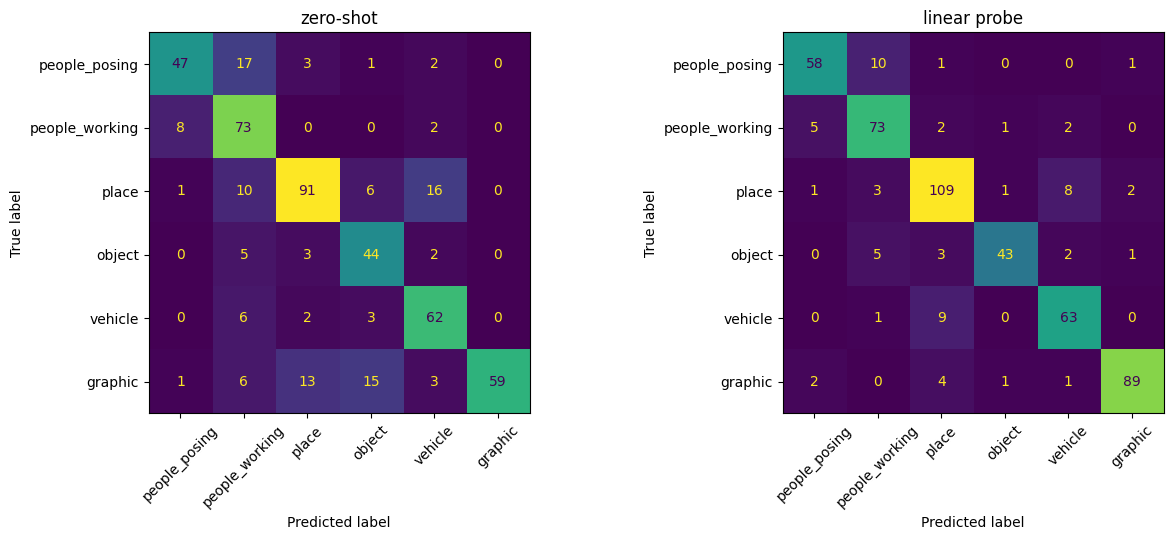

,file,label,guessed
5,ov-169ba25b.jpg,people_posing,people_working
8,ov-1f91bc9a.jpg,people_posing,people_working
13,ov-26e25ad3.jpg,people_posing,people_working
14,ov-2a857c12.jpg,people_posing,people_working
17,ov-3665090d.jpg,people_posing,people_working
28,ov-62edb2e2.jpg,people_posing,people_working
29,ov-66bc535e.jpg,people_posing,people_working
38,ov-888c4511.jpg,people_posing,people_working
41,ov-9e2aeb02.jpg,people_posing,people_working
51,ov-cc149cf7.jpg,people_posing,people_working


In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, predicted) in zip(
    axes, [("zero-shot", zero_shot), ("linear probe", probe)], strict=True
):
    ConfusionMatrixDisplay(
        confusion_matrix(y, predicted, labels=range(len(lab.CLASSES))), display_labels=lab.CLASSES
    ).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(name)
plt.tight_layout()
plt.show()
wrong = table[probe != y].assign(guessed=[lab.CLASSES[i] for i in probe[probe != y]])
wrong[["file", "label", "guessed"]].head(15)

In [8]:
rng = np.random.default_rng(0)
for share in (0.25, 0.5, 1.0):
    scores = []
    for k in range(5):
        train = np.flatnonzero(fold != k)
        keep = rng.choice(
            train, size=max(len(lab.CLASSES) * 2, int(len(train) * share)), replace=False
        )
        model = fit(X[keep], y[keep], 10.0)
        scores.append(f1_score(y[fold == k], model.predict(X[fold == k]), average="macro"))
    print(f"{share:>4.0%} of the training photos: macro-F1 {np.mean(scores):.3f}")

 25% of the training photos: macro-F1 0.716
 50% of the training photos: macro-F1 0.810
100% of the training photos: macro-F1 0.852


In [9]:
confidence = probe_proba.max(axis=1)
for line in (0.0, 0.4, 0.5, 0.6, 0.7, 0.8):
    sure = confidence >= line
    if sure.any():
        print(
            f"line {line:.1f}: labels {sure.mean():.0%} of photos, "
            f"right on {(probe[sure] == y[sure]).mean():.0%} of those"
        )
LINE = 0.6  # pick the lowest line where "right" is at least 90% on your real numbers

line 0.0: labels 100% of photos, right on 87% of those
line 0.4: labels 99% of photos, right on 87% of those
line 0.5: labels 96% of photos, right on 89% of those
line 0.6: labels 87% of photos, right on 92% of those
line 0.7: labels 82% of photos, right on 94% of those
line 0.8: labels 73% of photos, right on 96% of those


In [10]:
clients = pd.read_csv(lab.HERE / "client_types.csv")
client_X = ImageEncoder()(
    [lab.PHOTOS / c / f for c, f in zip(clients.client, clients.file, strict=True)]
)
client_y = np.array([lab.CLASSES.index(t) for t in clients.type])
final_C = choose_C(X, y, groups)
final = fit(X, y, final_C)
report("clients: zero-shot", (client_X @ T.T).argmax(axis=1), client_y)
report("clients: linear probe", final.predict(client_X), client_y)

clients: zero-shot     accuracy 0.792 | macro-F1 0.587
clients: linear probe  accuracy 0.875 | macro-F1 0.867


In [11]:
weights = {
    "classes": list(lab.CLASSES),
    "coef": final.coef_.round(7).tolist(),
    "intercept": final.intercept_.round(7).tolist(),
    "line": LINE,
    "C": final_C,
    "trained_on": {label: int((y == i).sum()) for i, label in enumerate(lab.CLASSES)},
    "embedding": json.loads((lab.HERE / "MODEL_LOCK.json").read_text())
    if (lab.HERE / "MODEL_LOCK.json").exists()
    else None,
}
(lab.HERE / "types.json").write_text(json.dumps(weights, indent=1) + "\n")


def numpy_probe(vectors, w):
    scores = vectors @ np.array(w["coef"]).T + np.array(w["intercept"])
    scores -= scores.max(axis=1, keepdims=True)  # softmax, written so it cannot overflow
    e = np.exp(scores)
    return e / e.sum(axis=1, keepdims=True)


saved = json.loads((lab.HERE / "types.json").read_text())
print(
    "numpy vs scikit-learn, biggest difference:",
    float(np.abs(numpy_probe(client_X, saved) - final.predict_proba(client_X)).max()),
)

numpy vs scikit-learn, biggest difference: 9.040198339915761e-09


In [12]:
guess = final.predict(client_X)
clients.assign(guessed=[lab.CLASSES[i] for i in guess])[guess != client_y]

,client,file,type,guessed
11,lone-star-roofing,lone-star-roofing-04.jpg,people_working,place
14,lone-star-roofing,lone-star-roofing-07.jpg,object,place
22,kowalski-plumbing,kowalski-plumbing-07.jpg,object,people_working
